In [10]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import RAW_DATA_DIR, dataset_overview, load_csv

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

## 1. Load the file

In [11]:
sms_raw = pd.read_csv("../data/raw/SMSSpamCollection",sep="\t",header=None,names=["v1", "v2"],encoding="utf-8")
print("Shape:", sms_raw.shape)
print("Columns:", list(sms_raw.columns))
sms_raw.head()

Shape: (5572, 2)
Columns: ['v1', 'v2']


,v1,v2
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


## 2. Inspect the extra columns and missing values

In [12]:
extra_cols = [c for c in sms_raw.columns if c.startswith("Unnamed")]
print("Extra unnamed columns:", extra_cols)
for col in extra_cols:
    print(col, "non-empty values:", int(sms_raw[col].notna().sum()))

print("\nMissing values:")
print(sms_raw.isna().sum())

Extra unnamed columns: []

Missing values:
v1    0
v2    0
dtype: int64


## 3. Class distribution

v1
ham     4825
spam     747
Name: count, dtype: int64

Percentage:
v1
ham     86.59
spam    13.41
Name: count, dtype: float64


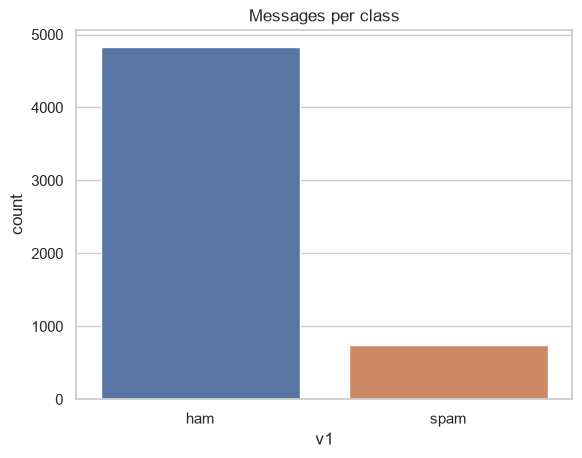

In [13]:
label_counts = sms_raw["v1"].str.strip().str.lower().value_counts()
print(label_counts)
print("\nPercentage:")
print((label_counts / label_counts.sum() * 100).round(2))

sns.countplot(data=sms_raw, x="v1", hue="v1", legend=False)
plt.title("Messages per class")
plt.show()

## 4. Duplicate messages

In [14]:
dupes = sms_raw.duplicated(subset=["v1", "v2"], keep=False)
print("Rows that are duplicates of another row:", int(dupes.sum()))
print("Unique messages:", sms_raw["v2"].nunique())

Rows that are duplicates of another row: 684
Unique messages: 5169


## 5. Message length by class

        count   mean   std   min    25%    50%    75%    max
label                                                       
ham    4825.0   71.5  58.4   2.0   33.0   52.0   93.0  910.0
spam    747.0  138.7  28.9  13.0  133.0  149.0  157.0  223.0


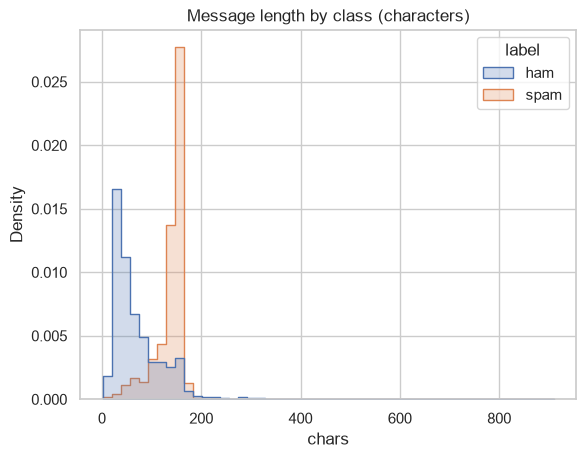

In [15]:
sms_len = sms_raw.assign(
    label=sms_raw["v1"].str.strip().str.lower(),
    chars=sms_raw["v2"].fillna("").str.len(),
)
print(sms_len.groupby("label")["chars"].describe().round(1))

sns.histplot(data=sms_len, x="chars", hue="label", bins=50, element="step", stat="density", common_norm=False)
plt.title("Message length by class (characters)")
plt.show()

## 6. Most frequent words per class

In [16]:
from collections import Counter

def top_words(messages, n=15):
    counter = Counter()
    for message in messages.fillna(""):
        counter.update(message.lower().split())
    return counter.most_common(n)

for label in ["spam", "ham"]:
    subset = sms_len.loc[sms_len["label"] == label, "v2"]
    print(f"--- top words in {label} ---")
    for word, count in top_words(subset):
        print(f"{word:<15} {count}")
    print()

--- top words in spam ---
to              685
a               375
call            342
your            263
you             252
the             204
for             202
or              188
free            180
2               169
is              152
ur              144
on              142
txt             136
have            135

--- top words in ham ---
i               2181
you             1669
to              1552
the             1125
a               1058
u               881
and             846
in              790
my              745
is              717
me              590
of              519
for             502
that            444
it              441

